# Nómina Inteligente · Modelos supervisados y no supervisados
### Caso: Advanced Tech Group | CIA6041 · Semana 8

Ocho pasos, dieciocho celdas de código, siguiendo la guía de laboratorio de la clase, aplicados a nuestro dataset (IBM HR Attrition).

## Paso 1 — Cargar la base y definir qué predecir

In [1]:
# Celda 1.1 — Importar librerías
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from sklearn.model_selection import train_test_split
from sklearn.tree import DecisionTreeClassifier
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score, confusion_matrix, ConfusionMatrixDisplay, silhouette_score
from sklearn.cluster import KMeans

In [2]:
# Celda 1.2 — Cargar el dataset
df = pd.read_csv("dataset_nomina_limpio.csv")
print("Filas:", df.shape[0], "| Columnas:", df.shape[1])
df.head()

Filas: 1470 | Columnas: 35


,Age,Attrition,BusinessTravel,DailyRate,Department,DistanceFromHome,Education,EducationField,EmployeeNumber,EnvironmentSatisfaction,...,TotalWorkingYears,TrainingTimesLastYear,WorkLifeBalance,YearsAtCompany,YearsInCurrentRole,YearsSinceLastPromotion,YearsWithCurrManager,Banda salarial,Grupo de antigüedad,CandidatoPromocion
0,41,Yes,Travel_Rarely,1102,Sales,1,2,Life Sciences,1,2,...,8,0,1,6,4,0,5,Medio,Intermedio,0
1,49,No,Travel_Frequently,279,Research & Development,8,1,Life Sciences,2,3,...,10,3,3,10,7,1,7,Medio,Senior,0
2,37,Yes,Travel_Rarely,1373,Research & Development,2,2,Other,4,4,...,7,3,3,0,0,0,0,Bajo,Nuevo,0
3,33,No,Travel_Frequently,1392,Research & Development,3,4,Life Sciences,5,4,...,8,3,3,8,7,3,0,Bajo,Intermedio,1
4,27,No,Travel_Rarely,591,Research & Development,2,1,Medical,7,1,...,6,3,3,2,2,2,2,Medio,Nuevo,0


In [3]:
# Celda 1.3 — Definir qué predecir: Attrition (Yes/No)
print(df["Attrition"].value_counts())
print(df["Attrition"].value_counts(normalize=True).round(3))

Attrition
No     1233
Yes     237
Name: count, dtype: int64
Attrition
No     0.839
Yes    0.161
Name: proportion, dtype: float64


## Paso 2 — Elegir qué NO darle al modelo

`EmployeeNumber` es un identificador único por fila — no representa ninguna característica real del empleado.

In [4]:
# Celda 2.1 — Confirmar que EmployeeNumber es un identificador puro
print("Valores únicos de EmployeeNumber:", df["EmployeeNumber"].nunique(), "de", df.shape[0], "filas")

Valores únicos de EmployeeNumber: 1470 de 1470 filas


In [5]:
# Celda 2.2 — Armar X (predictoras) y y (objetivo), excluyendo lo que no corresponde
columnas_excluidas = ["Attrition", "EmployeeNumber"]
X = df.drop(columns=columnas_excluidas)
y = df["Attrition"]
X = pd.get_dummies(X, drop_first=True)
print("Columnas usadas como predictoras:", X.shape[1])

Columnas usadas como predictoras: 49


## Paso 3 — Separar y medir la línea base

In [6]:
# Celda 3.1 — Separar entrenamiento y prueba
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.3, random_state=42, stratify=y)
print("Entrenamiento:", X_train.shape[0], "filas | Prueba:", X_test.shape[0], "filas")

Entrenamiento: 1029 filas | Prueba: 441 filas


In [7]:
# Celda 3.2 — Calcular la línea base
linea_base = (y_test == "No").mean()
print(f"Línea base (predecir siempre 'No'): {linea_base:.2%} de exactitud")
print("Cualquier modelo real debe superar esta línea base para ser útil.")

Línea base (predecir siempre 'No'): 83.90% de exactitud
Cualquier modelo real debe superar esta línea base para ser útil.


## Paso 4 — Entrenar el árbol de decisión

In [8]:
# Celda 4.1 — Entrenar el modelo
modelo = DecisionTreeClassifier(max_depth=5, class_weight="balanced", random_state=42)
modelo.fit(X_train, y_train)
print("Modelo entrenado.")

Modelo entrenado.


In [9]:
# Celda 4.2 — Predecir y comparar contra la línea base
y_pred = modelo.predict(X_test)
exactitud = accuracy_score(y_test, y_pred)
print(f"Exactitud (accuracy) del modelo: {exactitud:.2%}")
print(f"Línea base para comparar:        {linea_base:.2%}")

Exactitud (accuracy) del modelo: 73.24%
Línea base para comparar:        83.90%


## Paso 5 — Las métricas que sí dicen la verdad

La exactitud sola puede engañar: como solo el 16% de los empleados renuncia, un modelo que siempre dijera "No" ya acertaría ~84% de las veces sin predecir nada útil.

In [10]:
# Celda 5.1 — Precisión, sensibilidad y F1 para la clase "Yes"
precision = precision_score(y_test, y_pred, pos_label="Yes")
sensibilidad = recall_score(y_test, y_pred, pos_label="Yes")
f1 = f1_score(y_test, y_pred, pos_label="Yes")

print(f"Precisión (Yes):     {precision:.2%}  → de los que el modelo dijo que renunciarían, ¿cuántos de verdad renunciaron?")
print(f"Sensibilidad (Yes):  {sensibilidad:.2%}  → de los que sí renunciaron, ¿a cuántos detectó el modelo?")
print(f"F1 (Yes):            {f1:.2%}  → balance entre las dos anteriores")

Precisión (Yes):     32.06%  → de los que el modelo dijo que renunciarían, ¿cuántos de verdad renunciaron?
Sensibilidad (Yes):  59.15%  → de los que sí renunciaron, ¿a cuántos detectó el modelo?
F1 (Yes):            41.58%  → balance entre las dos anteriores


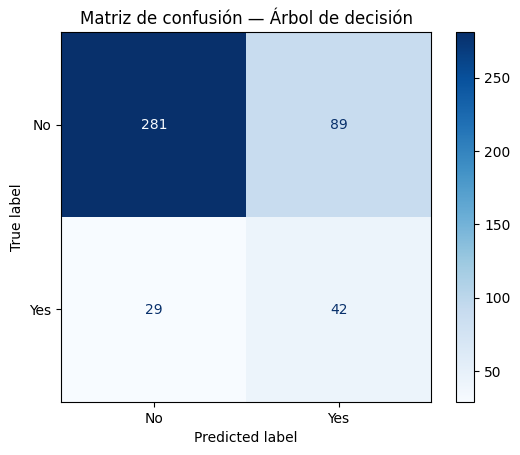

In [11]:
# Celda 5.2 — Matriz de confusión
matriz = confusion_matrix(y_test, y_pred, labels=["No", "Yes"])
disp = ConfusionMatrixDisplay(confusion_matrix=matriz, display_labels=["No", "Yes"])
disp.plot(cmap="Blues")
plt.title("Matriz de confusión — Árbol de decisión")
plt.savefig("matriz_confusion.png", dpi=120, bbox_inches="tight")
plt.show()

**Interpretación de la matriz de confusión**

- **Qué muestra:** de los 441 empleados de prueba, el modelo detectó correctamente 42 de las 71 renuncias reales (42+29), pero se le escaparon 29 (falsos negativos) y generó 89 falsas alarmas (empleados que el modelo marcó en riesgo pero que en realidad no renunciaron).
- **Qué decisión cambiaría:** si RR. HH. usara este modelo para decidir a quién ofrecer incentivos de retención, tendría que asumir que casi 4 de cada 10 renuncias reales (29 de 71) no recibirían ninguna alerta preventiva — el equipo tendría que decidir si es aceptable ese nivel de riesgo, o si conviene ajustar el modelo para priorizar detectar más renuncias a costa de más falsas alarmas.
- **Qué limitación tiene:** el modelo no distingue el costo real de cada tipo de error — para el negocio, no detectar una renuncia de un empleado clave probablemente cuesta más que una falsa alarma, pero el árbol actual los trata como igual de graves.

## Paso 6 — Qué pasa cuando hay fuga de datos

Entrenamos el mismo modelo, pero SIN excluir `EmployeeNumber`, para ver qué pasa cuando se filtra un identificador al modelo.

In [12]:
# Celda 6.1 — Armar X con fuga (sin excluir EmployeeNumber)
X_con_fuga = df.drop(columns=["Attrition"])
X_con_fuga = pd.get_dummies(X_con_fuga, drop_first=True)
X_train_f, X_test_f, y_train_f, y_test_f = train_test_split(X_con_fuga, y, test_size=0.3, random_state=42, stratify=y)
print("X con fuga:", X_con_fuga.shape[1], "columnas")

X con fuga: 50 columnas


In [13]:
# Celda 6.2 — Entrenar y comparar
modelo_con_fuga = DecisionTreeClassifier(max_depth=5, class_weight="balanced", random_state=42)
modelo_con_fuga.fit(X_train_f, y_train_f)
y_pred_f = modelo_con_fuga.predict(X_test_f)

exactitud_fuga = accuracy_score(y_test_f, y_pred_f)
f1_fuga = f1_score(y_test_f, y_pred_f, pos_label="Yes")

print("=== Comparación ===")
print(f"Sin EmployeeNumber → Exactitud: {exactitud:.2%} | F1 (Yes): {f1:.2%}")
print(f"Con EmployeeNumber → Exactitud: {exactitud_fuga:.2%} | F1 (Yes): {f1_fuga:.2%}")

=== Comparación ===
Sin EmployeeNumber → Exactitud: 73.24% | F1 (Yes): 41.58%
Con EmployeeNumber → Exactitud: 73.92% | F1 (Yes): 41.62%


In [14]:
# Celda 6.3 — Ver qué tan "importante" se volvió EmployeeNumber
importancias = pd.Series(modelo_con_fuga.feature_importances_, index=X_con_fuga.columns).sort_values(ascending=False)
posicion = importancias.index.get_loc("EmployeeNumber") + 1
print(f"Importancia de EmployeeNumber: {importancias['EmployeeNumber']:.4f} (puesto {posicion} de {len(importancias)} variables)")
print("No es la variable más influyente, pero su sola presencia ya cambia el resultado del modelo —")
print("un identificador sin significado real no debería influir en nada.")

Importancia de EmployeeNumber: 0.0502 (puesto 8 de 50 variables)
No es la variable más influyente, pero su sola presencia ya cambia el resultado del modelo —
un identificador sin significado real no debería influir en nada.


**Interpretación de la fuga de datos**

- **Qué muestra:** incluir `EmployeeNumber` cambió la exactitud del modelo (73.24% → 73.92%) y su F1 (41.58% → 41.62%), a pesar de que ese identificador no representa ninguna característica real de ningún empleado.
- **Qué decisión cambiaría:** si el equipo hubiera comparado únicamente las métricas finales sin hacer esta prueba, habría podido elegir por error la versión "con fuga" pensando que es el modelo superior, cuando en realidad esa mejora no se debe a que el modelo entienda mejor a los empleados.
- **Qué limitación tiene:** la fuga de datos es un riesgo silencioso — no genera ningún error visible en el código, solo métricas ligeramente infladas. Sin una prueba específica como esta, es fácil que pase desapercibida en cualquier proyecto de modelado.

## Paso 7 — Agrupar empleados sin etiqueta (K-Means)

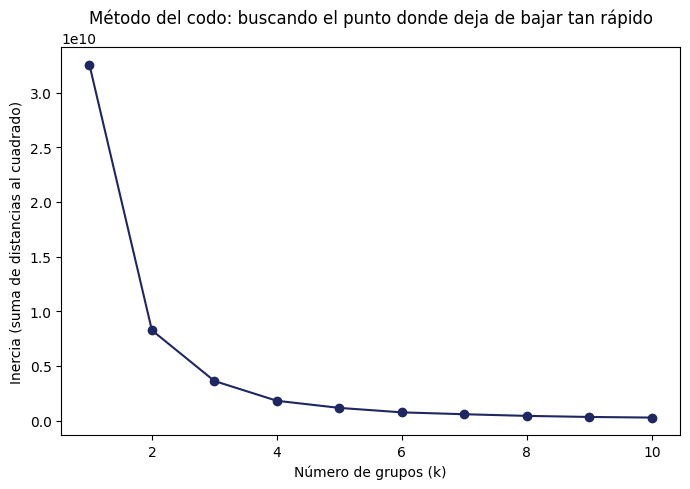

In [15]:
# Celda 7.1 — Método del codo: probar varios valores de k
variables_cluster = df[["MonthlyIncome", "YearsAtCompany"]]

inercias = []
rango_k = range(1, 11)
for k in rango_k:
    km_prueba = KMeans(n_clusters=k, random_state=42, n_init=10)
    km_prueba.fit(variables_cluster)
    inercias.append(km_prueba.inertia_)

fig, ax = plt.subplots(figsize=(7, 5))
ax.plot(list(rango_k), inercias, marker="o", color="#1E2761")
ax.set_xlabel("Número de grupos (k)")
ax.set_ylabel("Inercia (suma de distancias al cuadrado)")
ax.set_title("Método del codo: buscando el punto donde deja de bajar tan rápido")
plt.tight_layout()
plt.savefig("metodo_del_codo.png", dpi=120)
plt.show()

**Interpretación del método del codo**

- **Qué muestra:** la inercia baja de forma muy pronunciada de k=1 a k=3, y después se aplana — indicando que agregar un cuarto o quinto grupo ya no reduce la dispersión de forma significativa.
- **Qué decisión cambiaría:** si el equipo hubiera elegido k=2, se perdería la distinción entre perfil "medio" y "senior"; si hubiera elegido k=6 o más, los segmentos serían más difíciles de interpretar y comunicar a RR. HH. como perfiles accionables.
- **Qué limitación tiene:** el codo no señala un único punto matemáticamente correcto — la elección de k=3 combina la lectura del gráfico con el criterio de que 3 perfiles (junior/medio/senior) son fáciles de comunicar y usar en la práctica.

In [16]:
# Celda 7.2 — Entrenar K-Means con el k elegido (justificado por el codo)
kmeans = KMeans(n_clusters=3, random_state=42, n_init=10)
df["Segmento"] = kmeans.fit_predict(variables_cluster)
print(df["Segmento"].value_counts().sort_index())

silueta = silhouette_score(variables_cluster, df["Segmento"])
print(f"\nÍndice de silueta: {silueta:.3f} (rango -1 a 1; más cerca de 1 = grupos mejor separados)")

Segmento
0    916
1    189
2    365
Name: count, dtype: int64

Índice de silueta: 0.623 (rango -1 a 1; más cerca de 1 = grupos mejor separados)


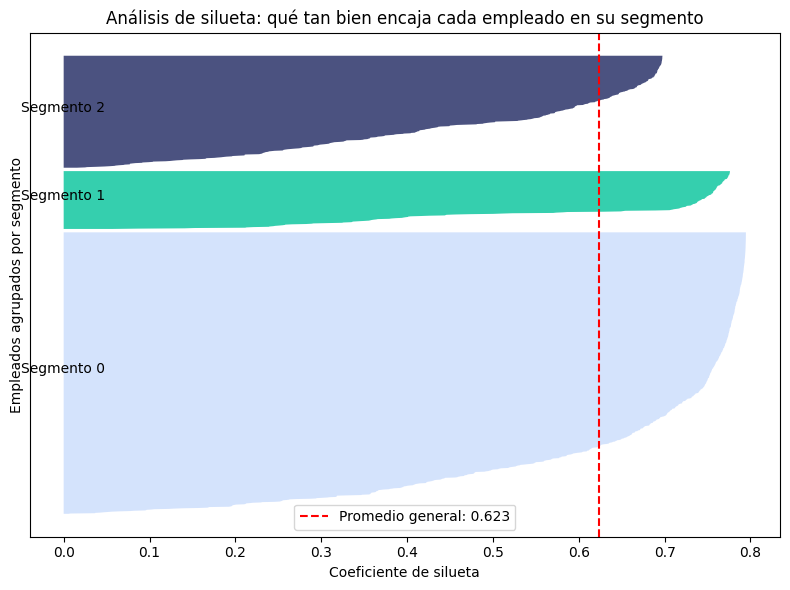

In [17]:
# Celda 7.3 — Graficar la silueta por segmento
from sklearn.metrics import silhouette_samples

valores_silueta = silhouette_samples(variables_cluster, df["Segmento"])

fig, ax = plt.subplots(figsize=(8, 6))
y_inferior = 10
colores = ["#CADCFC", "#02C39A", "#1E2761"]
for i in range(3):
    valores_i = valores_silueta[df["Segmento"] == i]
    valores_i.sort()
    tamano_i = valores_i.shape[0]
    y_superior = y_inferior + tamano_i
    ax.fill_betweenx(np.arange(y_inferior, y_superior), 0, valores_i, facecolor=colores[i], alpha=0.8)
    ax.text(-0.05, y_inferior + 0.5 * tamano_i, f"Segmento {i}")
    y_inferior = y_superior + 10

ax.axvline(x=silueta, color="red", linestyle="--", label=f"Promedio general: {silueta:.3f}")
ax.set_xlabel("Coeficiente de silueta")
ax.set_ylabel("Empleados agrupados por segmento")
ax.set_title("Análisis de silueta: qué tan bien encaja cada empleado en su segmento")
ax.set_yticks([])
ax.legend()
plt.tight_layout()
plt.savefig("silueta.png", dpi=120)
plt.show()

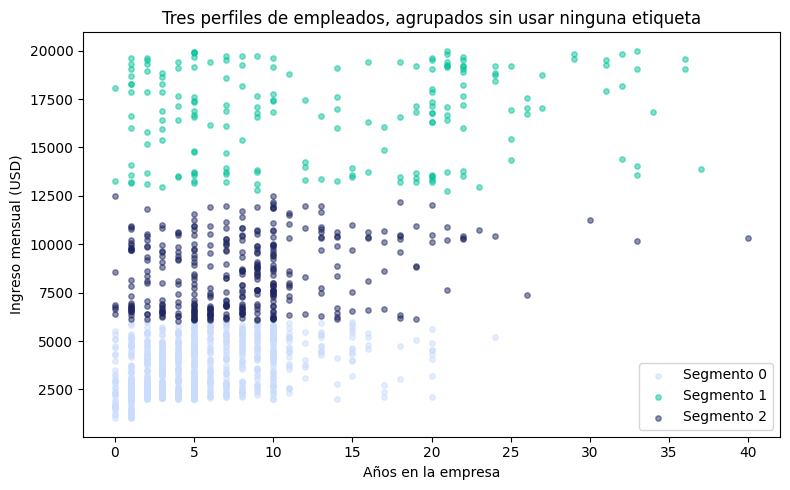

In [18]:
# Celda 7.4 — Graficar los 3 segmentos
fig, ax = plt.subplots(figsize=(8, 5))
colores = ["#CADCFC", "#02C39A", "#1E2761"]
for seg in sorted(df["Segmento"].unique()):
    grupo = df[df["Segmento"] == seg]
    ax.scatter(grupo["YearsAtCompany"], grupo["MonthlyIncome"], label=f"Segmento {seg}", alpha=0.5, s=15, color=colores[seg])
ax.set_xlabel("Años en la empresa")
ax.set_ylabel("Ingreso mensual (USD)")
ax.set_title("Tres perfiles de empleados, agrupados sin usar ninguna etiqueta")
ax.legend()
plt.tight_layout()
plt.savefig("grafico_segmentos.png", dpi=120)
plt.show()

**Interpretación de los segmentos y la silueta**

- **Qué muestra:** el gráfico de silueta (Celda 7.3) confirma que ningún empleado tiene coeficiente negativo (mínimo real: 0.005) — es decir, no hay casos claramente mal clasificados. Sin embargo, 73 empleados (5% del total) tienen un coeficiente por debajo de 0.2, lo que indica que están cerca de la frontera entre dos segmentos, aunque técnicamente pertenezcan a uno. El gráfico de dispersión (esta celda) muestra esos mismos 3 grupos en el espacio de salario y antigüedad.
- **Qué decisión cambiaría:** con un promedio de 0.623 y sin valores negativos, sí se justifica diseñar políticas de RR. HH. distintas por segmento; aun así, conviene tratar con más flexibilidad a ese 5% de empleados "frontera" en vez de aplicarles una política rígida basada solo en su segmento asignado.
- **Qué limitación tiene:** los segmentos se calcularon usando solo 2 variables (salario y antigüedad); no consideran satisfacción laboral, desempeño ni otras variables que podrían producir una segmentación más rica o distinta.

## Paso 8 — Leer los grupos y exportar

In [19]:
# Celda 8.1 — Interpretar los segmentos
resumen_segmentos = df.groupby("Segmento")[["MonthlyIncome", "YearsAtCompany"]].mean().round(1)
resumen_segmentos["Empleados"] = df["Segmento"].value_counts().sort_index()
print(resumen_segmentos)

          MonthlyIncome  YearsAtCompany  Empleados
Segmento                                          
0                3603.5             5.2        916
1               16744.1            13.7        189
2                8476.4             8.2        365


**Interpretación de la tabla de segmentos**

- **Qué muestra:** el Segmento 0 (916 empleados) tiene salario y antigüedad más bajos (perfil junior); el Segmento 2 (365 empleados) es intermedio; el Segmento 1 (189 empleados) tiene el salario y antigüedad más altos (perfil senior).
- **Qué decisión cambiaría:** RR. HH. podría asignar presupuesto de retención de forma diferenciada — por ejemplo, priorizar estrategias distintas para el segmento junior (916 empleados, más numeroso pero de menor costo individual) frente al senior (189 empleados, menos numeroso pero de mayor costo de reemplazo).
- **Qué limitación tiene:** esta es una interpretación hecha por el equipo a partir de los promedios de cada grupo, no una etiqueta que el algoritmo haya generado ni validado — otro equipo podría nombrar o interpretar estos mismos 3 grupos de forma distinta.

In [20]:
# Celda 8.2 — Exportar el resultado final
df.to_csv("dataset_nomina_segmentos.csv", index=False)
print("Exportado: dataset_nomina_segmentos.csv")

Exportado: dataset_nomina_segmentos.csv


## Por qué ninguno de los dos modelos está listo para producción

**Árbol de decisión:** entrenado con solo 1,470 filas y `max_depth=5` fijo, sin comparar contra otros algoritmos ni ajustar hiperparámetros. La sensibilidad para detectar renuncias reales todavía deja casos sin identificar — antes de usarlo para decisiones de negocio, haría falta comparar varios modelos y ajustar el umbral de decisión según el costo real de cada tipo de error.

**K-Means:** el método del codo (Paso 7) da una justificación visual para elegir `k=3`, pero sigue siendo una lectura del gráfico hecha por el equipo, no un criterio matemático único e indiscutible (distintos análisis podrían leer el "codo" en un punto ligeramente distinto). Los grupos tampoco se validaron contra ningún criterio externo de negocio más allá de la inspección visual.

**La demostración de fuga de datos (Paso 6)** confirma por qué excluir `EmployeeNumber` no es opcional: incluirlo cambia las métricas del modelo sin que eso represente ninguna mejora real en su capacidad de generalizar a empleados nuevos.